In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset shape: (2075259, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Missing values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Statistical summary:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [14]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce")

df["Global_active_power"] = pd.to_numeric(df["Global_active_power"], errors="coerce")

df.drop(columns=["Date", "Time"], inplace=True)

df.dropna(subset=["Datetime"], inplace=True)

df.set_index("Datetime", inplace=True)

df.sort_index(inplace=True)

print(df.head())
print("\nMissing values:")
print(df.isnull().sum())

KeyError: 'Date'

In [15]:
# Interpolate missing values using time
df["Global_active_power"] = df["Global_active_power"].interpolate(
    method="time"
)

# Handle any remaining missing values at the boundaries
df["Global_active_power"] = df["Global_active_power"].ffill().bfill()

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Global_active_power          0
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [16]:
hourly_df = df.resample("h").mean()

hourly_df["Global_active_power"] = hourly_df[
    "Global_active_power"
].interpolate(method="time").ffill().bfill()

print("Hourly dataset shape:", hourly_df.shape)

Hourly dataset shape: (34589, 7)


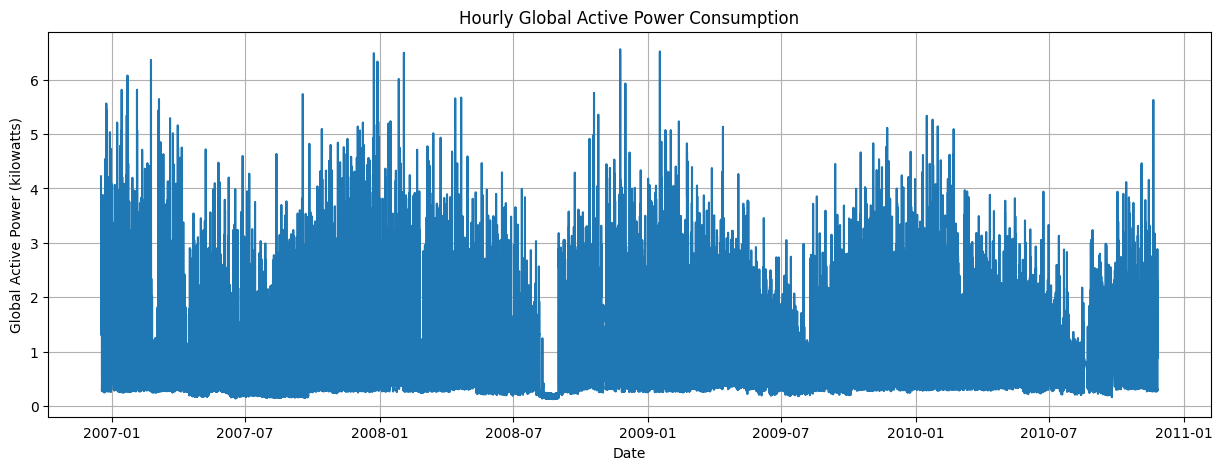

In [11]:
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_df.index,
    hourly_df["Global_active_power"]
)

plt.title("Hourly Global Active Power Consumption")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kilowatts)")
plt.grid(True)

plt.show()

In [24]:
data = hourly_df[["Global_active_power"]].values

split_index = int(len(data) * 0.80)

train_data = data[:split_index]
test_data = data[split_index:]

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Training data shape: (27671, 1)
Testing data shape: (6918, 1)


In [23]:
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train_data)

test_scaled = scaler.transform(test_data)

In [25]:
def create_sequences(data, sequence_length=24):

    X = []
    y = []

    for i in range(sequence_length, len(data)):

        # Previous 24 hours
        X.append(data[i-sequence_length:i])

        # Next hour
        y.append(data[i])

    return np.array(X), np.array(y)

In [26]:
sequence_length = 24

X_train, y_train = create_sequences(
    train_scaled,
    sequence_length
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (27647, 24, 1)
y_train shape: (27647, 1)


In [28]:
combined_data = np.concatenate(
    (train_scaled, test_scaled),
    axis=0
)

X_test = []
y_test = []

for i in range(split_index, len(combined_data)):

    X_test.append(
        combined_data[i-sequence_length:i]
    )

    y_test.append(
        combined_data[i]
    )

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (6918, 24, 1)
y_test shape: (6918, 1)


In [29]:
rnn_model = Sequential([

    SimpleRNN(
        units=50,
        activation="tanh",
        input_shape=(sequence_length, 1)
    ),

    Dropout(0.2),

    Dense(1)
])

rnn_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
early_stop_rnn = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_rnn = rnn_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop_rnn],
    shuffle=False
)

Epoch 1/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0092 - mae: 0.0680 - val_loss: 0.0102 - val_mae: 0.0743
Epoch 2/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0092 - mae: 0.0682 - val_loss: 0.0101 - val_mae: 0.0741
Epoch 3/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 0.0092 - mae: 0.0680 - val_loss: 0.0102 - val_mae: 0.0742
Epoch 4/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 0.0092 - mae: 0.0678 - val_loss: 0.0101 - val_mae: 0.0736
Epoch 5/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0092 - mae: 0.0677 - val_loss: 0.0102 - val_mae: 0.0738
Epoch 6/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0092 - mae: 0.0675 - val_loss: 0.0101 - val_mae: 0.0737
Epoch 7/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0092 - mae: 0.0675 - val_loss: 0.0101 - val_mae: 0.0737
Epoch 8/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0091 - mae: 0.0674 - val_loss: 0.0101 - val_mae: 0.0735
Epoch 9/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - l

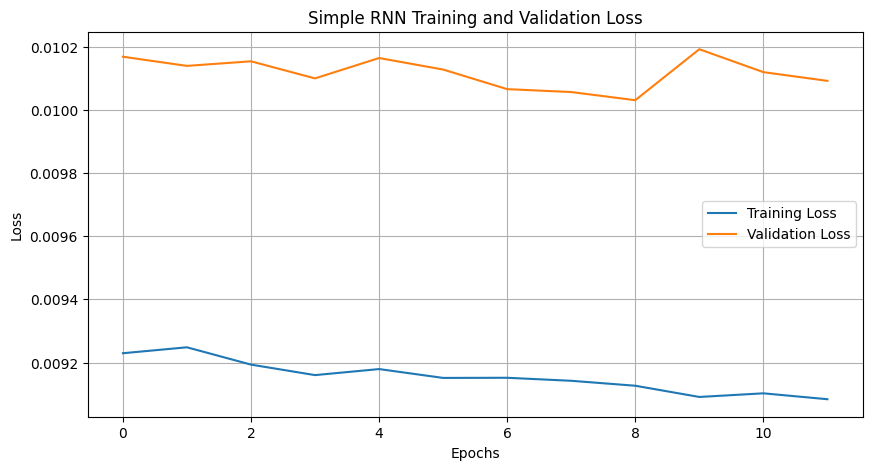

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(history_rnn.history["loss"], label="Training Loss")
plt.plot(history_rnn.history["val_loss"], label="Validation Loss")

plt.title("Simple RNN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [38]:
# Build LSTM model
lstm_model = Sequential([

    LSTM(
        units=50,
        activation="tanh",
        input_shape=(sequence_length, 1)
    ),

    Dropout(0.2),

    Dense(1)
])

# Compile model
lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

# Model summary
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
early_stop_lstm = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop_lstm],
    shuffle=False
)

Epoch 1/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - loss: 0.0135 - mae: 0.0860 - val_loss: 0.0118 - val_mae: 0.0799
Epoch 2/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 0.0102 - mae: 0.0726 - val_loss: 0.0111 - val_mae: 0.0773
Epoch 3/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0100 - mae: 0.0711 - val_loss: 0.0109 - val_mae: 0.0769
Epoch 4/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0093 - mae: 0.0680 - val_loss: 0.0099 - val_mae: 0.0727
Epoch 5/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 0.0091 - mae: 0.0667 - val_loss: 0.0099 - val_mae: 0.0720
Epoch 6/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0089 - mae: 0.0659 - val_loss: 0.0097 - val_mae: 0.0711
Epoch 7/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0088 - mae: 0.0654 - val_loss: 0.0096 - val_mae: 0.0704
Epoch 8/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0087 - mae: 0.0650 - val_loss: 0.0096 - val_mae: 0.0703
Epoch 9/15
778/778 ━━━━━━━━━━━━━━━━━━━━ 9

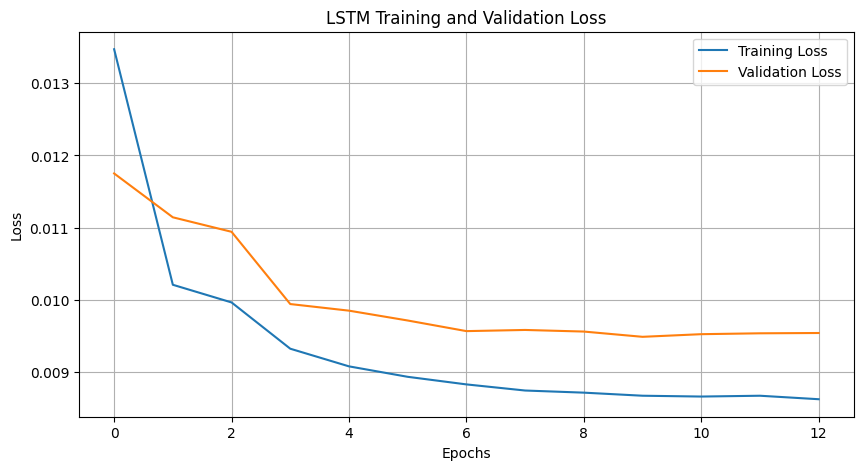

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history["loss"], label="Training Loss")
plt.plot(history_lstm.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [41]:
# RNN predictions
rnn_predictions = rnn_model.predict(X_test)

# LSTM predictions
lstm_predictions = lstm_model.predict(X_test)

print("RNN prediction shape:", rnn_predictions.shape)
print("LSTM prediction shape:", lstm_predictions.shape)

217/217 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
217/217 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
RNN prediction shape: (6918, 1)
LSTM prediction shape: (6918, 1)


In [42]:
rnn_predictions_original = scaler.inverse_transform(
    rnn_predictions
)

lstm_predictions_original = scaler.inverse_transform(
    lstm_predictions
)

y_test_original = scaler.inverse_transform(y_test)

print("Actual values:")
print(y_test_original[:5])

print("\nRNN predictions:")
print(rnn_predictions_original[:5])

print("\nLSTM predictions:")
print(lstm_predictions_original[:5])

Actual values:
[[0.47773333]
 [0.65526667]
 [1.43636667]
 [2.3199    ]
 [2.15993333]]

RNN predictions:
[[0.67282414]
 [0.98948765]
 [1.1644248 ]
 [1.6913952 ]
 [2.2287843 ]]

LSTM predictions:
[[0.5741034]
 [0.8287079]
 [1.2206571]
 [1.9944305]
 [2.4125743]]


In [43]:
def evaluate_model(actual, predicted, model_name):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    print(f"\n{model_name} Performance")

    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))

    return mae, mse, rmse

In [44]:
rnn_metrics = evaluate_model(
    y_test_original,
    rnn_predictions_original,
    "Simple RNN"
)


Simple RNN Performance
MAE: 0.3828
MSE: 0.2676
RMSE: 0.5173


In [45]:
lstm_metrics = evaluate_model(
    y_test_original,
    lstm_predictions_original,
    "LSTM"
)


LSTM Performance
MAE: 0.3684
MSE: 0.2572
RMSE: 0.5072


In [46]:
comparison = pd.DataFrame({

    "Model": ["Simple RNN", "LSTM"],

    "MAE": [
        rnn_metrics[0],
        lstm_metrics[0]
    ],

    "MSE": [
        rnn_metrics[1],
        lstm_metrics[1]
    ],

    "RMSE": [
        rnn_metrics[2],
        lstm_metrics[2]
    ]

})

print(comparison)

        Model       MAE       MSE      RMSE
0  Simple RNN  0.382755  0.267621  0.517321
1        LSTM  0.368354  0.257202  0.507151


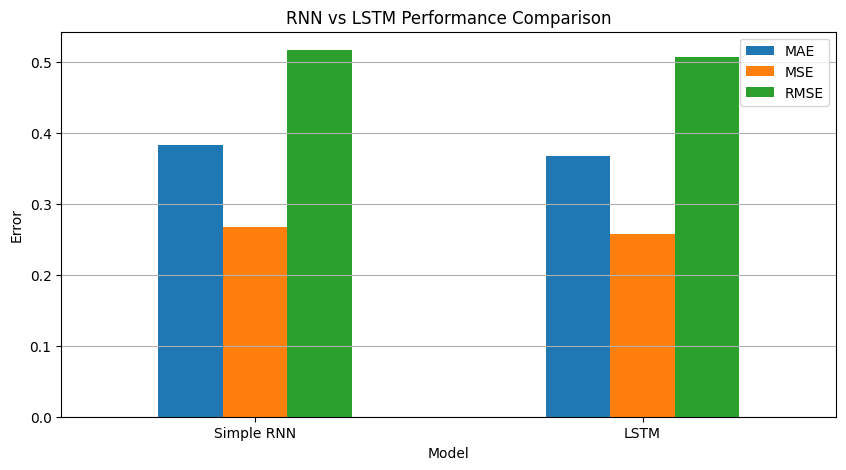

In [47]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("RNN vs LSTM Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

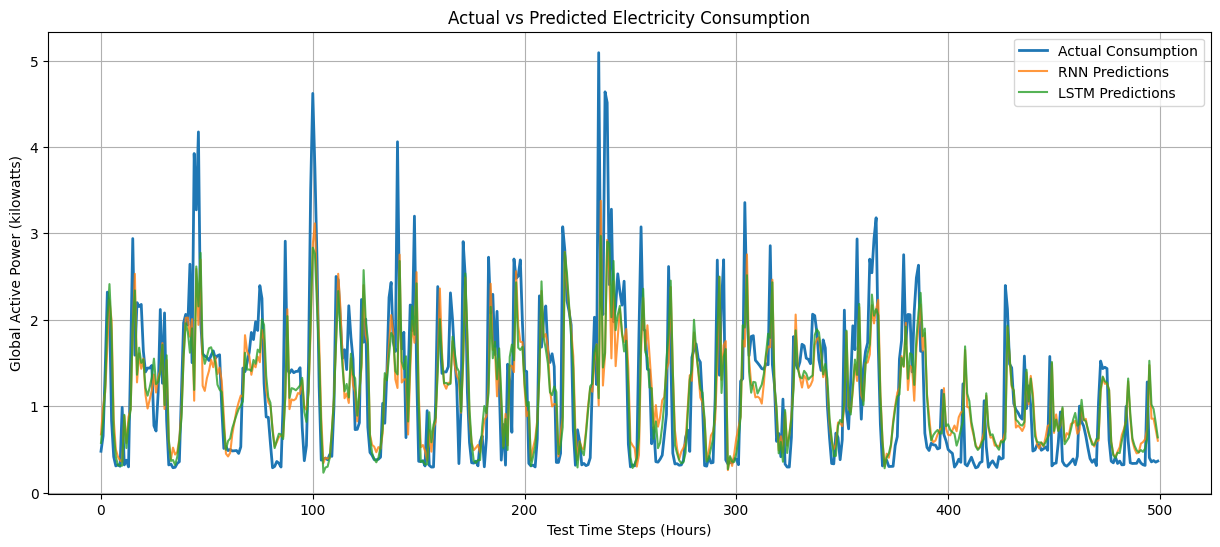

In [48]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_original[:500],
    label="Actual Consumption",
    linewidth=2
)

plt.plot(
    rnn_predictions_original[:500],
    label="RNN Predictions",
    alpha=0.8
)

plt.plot(
    lstm_predictions_original[:500],
    label="LSTM Predictions",
    alpha=0.8
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Time Steps (Hours)")
plt.ylabel("Global Active Power (kilowatts)")

plt.legend()
plt.grid(True)

plt.show()

The vanishing gradient problem happens when gradients become very small while being passed backward through multiple time steps during training. As a result, the model finds it difficult to learn information from the earlier parts of a sequence.
- Simple RNN: It may struggle to remember information from previous time steps, especially when dealing with long sequences.
- LSTM: It uses a memory cell and gating mechanisms to retain important information and reduce the impact of vanishing gradients.
- Result: LSTM is generally better at learning long-term dependencies compared to a Simple RNN, but its performance still depends on the dataset and model configuration